<a href="https://colab.research.google.com/github/chawlaniharika23/Fraud_Detection_Research/blob/main/notebooks/07_cross_dataset_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Mount Google Drive at the same mount point used by Notebooks 01–06.
from google.colab import drive
from pathlib import Path

if not Path("/content/drive2/MyDrive").exists():
    drive.mount("/content/drive2")
else:
    print("Google Drive is already mounted at /content/drive2.")

# Notebook 07 — Cross-dataset performance analysis
# Uses only results produced by Notebooks 01 and 06.
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_ROOT = Path("/content/drive2/MyDrive/fraud-detection-data")
if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_ROOT}. Mount Google Drive at /content/drive2 first."
    )

# All outputs are written directly to fraud-detection-data; no new folders.
COMPARISON_DIR = DATA_ROOT

required_files = [
    DATA_ROOT / "ieee_test_results.csv",
    DATA_ROOT / "paysim_results.csv",
    DATA_ROOT / "stacking_experiment_summary.json",
    DATA_ROOT / "notebook01_run_manifest.json",
]
missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Required Notebook 01/05/06 outputs are missing:\\n" + "\\n".join(missing)
    )

ieee_df = pd.read_csv(DATA_ROOT / "ieee_test_results.csv")
paysim_df = pd.read_csv(DATA_ROOT / "paysim_results.csv")
with open(DATA_ROOT / "stacking_experiment_summary.json", encoding="utf-8") as f:
    stacking_summary = json.load(f)
with open(DATA_ROOT / "notebook01_run_manifest.json", encoding="utf-8") as f:
    data_manifest = json.load(f)

print("IEEE-CIS results:", ieee_df.shape)
print("PaySim results:", paysim_df.shape)
print("\\nIEEE-CIS test results:")
display(ieee_df.round(5))
print("\\nPaySim test results:")
display(paysim_df.round(5))


Mounted at /content/drive2
IEEE-CIS results: (7, 16)
PaySim results: (4, 20)
\nIEEE-CIS test results:


,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,FPR,Brier_Score,TN,FP,FN,TP,Model
0,0.22882,0.96605,0.70352,0.51507,0.42134,0.46351,0.87928,0.46069,0.44857,0.01430,0.02441,84275,1223,1784,1299,Dynamic_Stacking
1,0.50000,0.92196,0.76416,0.24453,0.59455,0.34654,0.87178,0.45944,0.34791,0.06624,0.08057,79835,5663,1250,1833,RF
2,0.50000,0.79928,0.78440,0.12189,0.76841,0.21041,0.85941,0.40292,0.25191,0.19961,0.15226,68432,17066,714,2369,GBT
3,0.50000,0.86314,0.75276,0.15097,0.63412,0.24387,0.77861,0.37132,0.26225,0.12860,0.12108,74503,10995,1128,1955,DT
4,0.50000,0.96606,0.64256,0.52211,0.29484,0.37687,0.82345,0.33941,0.37646,0.00973,0.02997,84666,832,2174,909,MLP
5,0.50000,0.60687,0.72178,0.07052,0.84528,0.13018,0.81602,0.15900,0.16487,0.40173,0.24816,51151,34347,477,2606,LR
6,0.50000,0.95371,0.56409,0.23419,0.14531,0.17934,0.80927,0.15456,0.16162,0.01713,0.03562,84033,1465,2635,448,SVM


\nPaySim test results:


,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,FPR,Brier_Score,TN,FP,FN,TP,Dataset,Feature_Set,Model,Training_Time_Seconds,Test_Prediction_Time_Seconds
0,0.71626,1.00000,0.99975,1.00000,0.99950,0.99975,1.00000,1.00000,0.99975,0.00000,0.00005,950385,0,2,4006,PaySim,Extended,RF,830.63826,3.02323
1,0.89780,0.99819,0.80480,0.93676,0.60978,0.73870,0.99781,0.84538,0.75502,0.00017,0.01466,950220,165,1564,2444,PaySim,Realtime,RF,548.62690,2.13385
2,0.99998,0.99752,0.71217,0.96758,0.42440,0.59001,0.98815,0.70344,0.63996,0.00006,0.01705,950328,57,2307,1701,PaySim,Extended,LR,24.36582,0.15107
3,1.00000,0.99671,0.61387,0.95104,0.22779,0.36755,0.98148,0.41636,0.46460,0.00005,0.03556,950338,47,3095,913,PaySim,Realtime,LR,18.71387,0.08590


In [2]:
# Dataset characteristics from Notebook 01's actual-data manifest.
# IEEE-CIS figures refer to its labelled training file; PaySim figures refer
# to the full PaySim source file. They are descriptive, not test-set metrics.
dataset_comparison = pd.DataFrame([
    {
        "Dataset": "IEEE-CIS",
        "Source_Rows": int(data_manifest["ieee_train_rows"]),
        "Fraud_Cases": int(data_manifest["ieee_train_fraud_count"]),
        "Fraud_Rate_Percent": float(data_manifest["ieee_train_fraud_rate_percent"]),
        "Count_Basis": "Labelled IEEE-CIS training file"
    },
    {
        "Dataset": "PaySim",
        "Source_Rows": int(data_manifest["paysim_rows"]),
        "Fraud_Cases": int(data_manifest["paysim_fraud_count"]),
        "Fraud_Rate_Percent": float(data_manifest["paysim_fraud_rate_percent"]),
        "Count_Basis": "Full PaySim source file"
    }
])

dataset_comparison.to_csv(
    COMPARISON_DIR / "cross_dataset_dataset_comparison.csv",
    index=False
)
display(dataset_comparison)


,Dataset,Source_Rows,Fraud_Cases,Fraud_Rate_Percent,Count_Basis
0,IEEE-CIS,590540,20663,3.499001,Labelled IEEE-CIS training file
1,PaySim,6362620,8213,0.129082,Full PaySim source file


In [3]:
#Identify the best model for each dataset
ieee_best = ieee_df.sort_values(
    "PR_AUC", ascending=False
).iloc[0]

paysim_best = paysim_df.sort_values(
    "PR_AUC", ascending=False
).iloc[0]

best_models = pd.DataFrame([
    {
        "Dataset": "IEEE-CIS",
        "Best_Model": ieee_best["Model"],
        "Precision": ieee_best["Precision"],
        "Recall": ieee_best["Recall"],
        "F1": ieee_best["F1"],
        "ROC_AUC": ieee_best["ROC_AUC"],
        "PR_AUC": ieee_best["PR_AUC"]
    },
    {
        "Dataset": "PaySim",
        "Best_Model": (
            paysim_best["Feature_Set"] + " " +
            paysim_best["Model"]
        ),
        "Precision": paysim_best["Precision"],
        "Recall": paysim_best["Recall"],
        "F1": paysim_best["F1"],
        "ROC_AUC": paysim_best["ROC_AUC"],
        "PR_AUC": paysim_best["PR_AUC"]
    }
])

best_models.to_csv(
    COMPARISON_DIR / "cross_dataset_best_model_comparison.csv",
    index=False
)

display(best_models.round(4))

,Dataset,Best_Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,IEEE-CIS,Dynamic_Stacking,0.5151,0.4213,0.4635,0.8793,0.4607
1,PaySim,Extended RF,1.0000,0.9995,0.9998,1.0000,1.0000


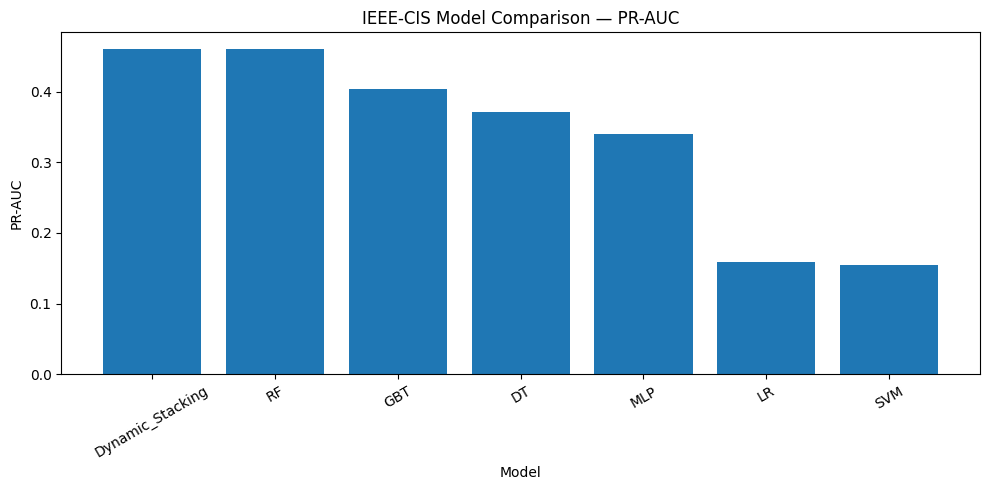

In [4]:
#Plot IEEE-CIS model performance
plt.figure(figsize=(10, 5))

plt.bar(
    ieee_df["Model"],
    ieee_df["PR_AUC"]
)

plt.title("IEEE-CIS Model Comparison — PR-AUC")
plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "cross_dataset_ieee_model_comparison.png",
    dpi=300
)

plt.show()

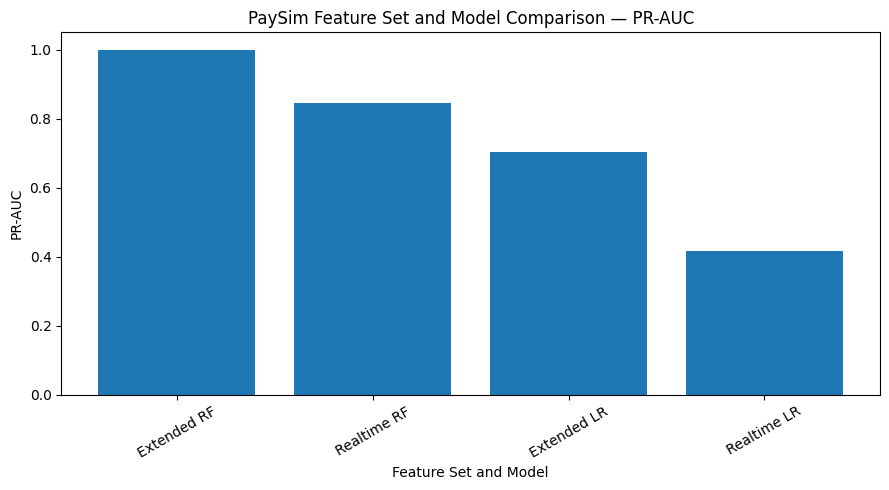

In [5]:
#Plot PaySim model performance
plt.figure(figsize=(9, 5))

paysim_labels = (
    paysim_df["Feature_Set"] + " " +
    paysim_df["Model"]
)

plt.bar(
    paysim_labels,
    paysim_df["PR_AUC"]
)

plt.title("PaySim Feature Set and Model Comparison — PR-AUC")
plt.xlabel("Feature Set and Model")
plt.ylabel("PR-AUC")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "cross_dataset_paysim_model_comparison.png",
    dpi=300
)

plt.show()

In [6]:
# Summarize results without treating scores across different datasets as directly comparable.
research_conclusion = f"""CROSS-DATASET MODEL RESULTS

IEEE-CIS best by test PR-AUC: {ieee_best['Model']} (PR-AUC {ieee_best['PR_AUC']:.4f}).
PaySim best by test PR-AUC: {paysim_best['Feature_Set']} {paysim_best['Model']} (PR-AUC {paysim_best['PR_AUC']:.4f}).

The datasets have different feature spaces, fraud prevalence, time periods, and validation/test protocols. Compare models within each dataset; do not interpret the raw PR-AUC values as a cross-dataset ranking.

PaySim's extended feature set includes post-transaction balances. Its results are an offline comparison and should not be presented as real-time performance. Use the RealTime feature set for the deployable scenario.

Thresholds are selected using validation data. Report test results once after model and threshold selection.
"""
with open(COMPARISON_DIR / "cross_dataset_research_conclusion.txt", "w") as f:
    f.write(research_conclusion)
print(research_conclusion)


CROSS-DATASET MODEL RESULTS

IEEE-CIS best by test PR-AUC: Dynamic_Stacking (PR-AUC 0.4607).
PaySim best by test PR-AUC: Extended RF (PR-AUC 1.0000).

The datasets have different feature spaces, fraud prevalence, time periods, and validation/test protocols. Compare models within each dataset; do not interpret the raw PR-AUC values as a cross-dataset ranking.

PaySim's extended feature set includes post-transaction balances. Its results are an offline comparison and should not be presented as real-time performance. Use the RealTime feature set for the deployable scenario.

Thresholds are selected using validation data. Report test results once after model and threshold selection.



In [7]:
#Combine all experiment results
ieee_export = ieee_df.copy()
ieee_export["Dataset"] = "IEEE-CIS"

paysim_export = paysim_df.copy()
paysim_export["Dataset"] = "PaySim"

combined_results = pd.concat(
    [ieee_export, paysim_export],
    ignore_index=True,
    sort=False
)

combined_results.to_csv(
    COMPARISON_DIR / "cross_dataset_all_experiment_results.csv",
    index=False
)

print("All cross-dataset analysis outputs saved directly in fraud-detection-data.")
print("\nFiles created:")

for filename in sorted(DATA_ROOT.iterdir()):
    print("-", filename.name)

print("\\nNotebook 07 generated files:")
for path in sorted(DATA_ROOT.glob("cross_dataset_*")):
    if path.is_file():
        print(f"{path.name} — {path.stat().st_size / (1024**2):.2f} MB")


All cross-dataset analysis outputs saved directly in fraud-detection-data.

Files created:
- DT_model.joblib
- GBT_model.joblib
- LR_model.joblib
- MLP_model.joblib
- NN_model.joblib
- RF_model.joblib
- SVM_model.joblib
- all_test_experiment_results.csv
- archive.zip
- base_model_order.json
- base_model_results.csv
- base_model_run_manifest.json
- base_model_threshold_analysis.csv
- base_model_validation_probabilities.npz
- categorical_encoder.joblib
- categorical_imputer.joblib
- cross_dataset_all_experiment_results.csv
- cross_dataset_best_model_comparison.csv
- cross_dataset_dataset_comparison.csv
- cross_dataset_ieee_model_comparison.png
- cross_dataset_paysim_model_comparison.png
- cross_dataset_research_conclusion.txt
- eda_dataset_summary.csv
- eda_dataset_summary.json
- extended_LR_pipeline.joblib
- extended_RF_pipeline.joblib
- extratrees_feature_ranker.joblib
- feature_selection_output_summary.csv
- frequency_maps.joblib
- ieee
- ieee-fraud-detection.zip
- ieee_X_test.parquet